# Інфекційні захворювання: від CSV до SQL-аналізу

Фінальний проєкт із реляційних баз даних: імпорт у PostgreSQL, нормалізація
до третьої нормальної форми, статистика Number_rabies, календарні дати
та дві власні функції.

**Запуск у Google Colab:** відкрийте цей notebook, оберіть звичайне середовище
з CPU та натисніть **Runtime → Run all**. Перша клітинка автоматично встановить
відсутні залежності, відновить вкладені файли й запустить окремий PostgreSQL 16.
Початкове налаштування може тривати кілька хвилин.

Джерело — [infectious_cases.csv з умови LMS](https://drive.google.com/file/d/1dQf-uVXzYPYYGgXsG1y4Q1qDdhP2miZl/view?usp=drive_link):
10 521 спостереження, 12 колонок, 245 пар Entity/Code, 1920–2023 роки.
Незмінений CSV і всі SQL-файли вкладені в notebook.

SHA-256 CSV: `226a0ff1916de44182d881b00d21cd59c1d58ae2ff6ec47d7a8042d7bc03f289`.

## Підготовка середовища

Кожний повний запуск створює нову ізольовану базу. Попереднє підключення
закривається при повторному запуску першої клітинки. Сумісні бібліотеки Colab
зберігаються; для Python 3.13 у Colab використовується системний PostgreSQL 16.
Поточна дата в усіх SQL-запитах визначається під час виконання в часовому поясі UTC.

In [1]:
#@title Підготувати PostgreSQL 16 та відновити файли
import base64
import hashlib
import json
from pathlib import Path
import sys
import tempfile
import zlib

previous_run = globals().get("run")
if previous_run is not None:
    previous_run.close()
previous_bundle = globals().get("_bundle_directory")
if previous_bundle is not None:
    previous_bundle.cleanup()

BUNDLE_SHA256 = '53212792744d4ad7a73a10a9823e12cd37c1b9cc4c14dc32670c54ff863eeff5'
FILE_SHA256 = {
    "data/infectious_cases.csv": "226a0ff1916de44182d881b00d21cd59c1d58ae2ff6ec47d7a8042d7bc03f289",
    "sql/01_schema.sql": "55a484302323f8850a8ff33990d4c3bb6ef81e686bf3e6ac33430b7e5900904b",
    "sql/02_normalize.sql": "abe6510f68a8f5c962039798e8dc6699f7f52715dcde9ab63754797f5b75ac35",
    "sql/03_analysis.sql": "c90d85ef106cbb2b7497be692f48111e52092506ad40645f5c0f682887b633cb",
    "sql/04_dates.sql": "dc6cb0633ac80af083c7b85ee0c6a4856a4af22d960d6645531f842850ab54b7",
    "sql/05_functions.sql": "195587ecac925fccd6902b389f16f2480061431b0d898542bfaa2bf2a6e0db5b",
    "sql/06_function_examples.sql": "0392c070cc94edf319985de714151a6b8842eac3102e4dd791ff57e058148c96",
    "sql/07_validation.sql": "1d1aa3efda4dd645811baf456f6402fe78d95f2222f5135f10a000230b243b4f",
    "assets/runtime_bootstrap.py": "83e7dbe1ddc4839127c6e34fe7602c814ff71d8783d4694a3a0f46065dd37281",
    "assets/project.py": "680cfd0c281ad5a4a6a623250a2389dbe1bbf0506651d1b8d9e9519652cf177d",
    "assets/checks.py": "91ba1f49897dfe4ea4e1052c7474be2dfb4c87cdf03a45c7406d63439c5421ce"
}
EMBEDDED_BUNDLE = '...'
compressed = base64.b64decode(EMBEDDED_BUNDLE, validate=True)
if hashlib.sha256(compressed).hexdigest() != BUNDLE_SHA256:
    raise ValueError("Контрольна сума вкладеного пакета не збігається.")
payload = json.loads(zlib.decompress(compressed))
if set(payload) != set(FILE_SHA256):
    raise ValueError("Набір вкладених файлів не збігається з переліком.")
_bundle_directory = tempfile.TemporaryDirectory(prefix="infectious-cases-")
PROJECT_ROOT = Path(_bundle_directory.name) / "project"
PROJECT_ROOT.mkdir()
for relative, expected_sha256 in FILE_SHA256.items():
    relative_path = Path(relative)
    if relative_path.is_absolute() or ".." in relative_path.parts:
        raise ValueError("Некоректний шлях вкладеного файла.")
    data = base64.b64decode(payload[relative], validate=True)
    if hashlib.sha256(data).hexdigest() != expected_sha256:
        raise ValueError(f"Контрольна сума не збігається: {relative}")
    destination = PROJECT_ROOT / relative_path
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_bytes(data)

assets_path = str(PROJECT_ROOT / "assets")
sys.path.insert(0, assets_path)
for module_name in ("runtime_bootstrap", "project", "checks"):
    sys.modules.pop(module_name, None)
from runtime_bootstrap import setup_dependencies
package_versions = setup_dependencies({
    "pgserver": "0.1.4",
    "psycopg2-binary": "2.9.12",
    "pandas": "2.3.3",
    "matplotlib": "3.9.4",
})

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Code, Markdown, display
from project import ProjectRun
from checks import check_project

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

def sql_file(name):
    return (PROJECT_ROOT / "sql" / name).read_text(encoding="utf-8")

def show_sql(sql):
    display(Code(sql, language="sql"))

def result(name, sql, rows=None):
    show_sql(sql)
    frame = run.query(sql)
    run.save_results(name, frame)
    display(frame if rows is None else frame.head(rows))
    return frame

run = ProjectRun(PROJECT_ROOT)
display(run.environment)
print("Вкладені файли відновлено:", len(FILE_SHA256))
print("Результати цього запуску:", PROJECT_ROOT / "results")

Python: 3.9.25 ; packages: {'pgserver': '0.1.4', 'psycopg2': '2.9.12', 'pandas': '2.3.3', 'matplotlib': '3.9.4'}
PostgreSQL backend: pgserver 0.1.4


,postgresql,run_date,time_zone
0,"PostgreSQL 16.2 on aarch64-apple-darwin23.5.0, compiled by Apple clang version 15.0.0 (clang-1500.0.40.1), 64-bit",2026-10-18,UTC


Вкладені файли відновлено: 11
Результати цього запуску: /var/folders/tp/kf9whtnd5_s2_d1h5b29w5h00000gn/T/infectious-cases-m8at3ozc/project/results


## 1. Завантаження даних

Схему `pandemic` встановлюємо за замовчуванням командою `SET search_path`.
CSV надходить у `infectious_cases` через `COPY FROM STDIN`: порожнє поле
стає SQL `NULL`, а числовий нуль залишається нулем. Дев’ять показників мають
тип `NUMERIC` без обмеження кількості десяткових знаків. Доданий
`source_row_id` нумерує записи для подальшого зіставлення.

In [2]:
show_sql(run.script("01_schema.sql"))
copy_sql = """COPY pandemic.infectious_cases (
    entity, code, year, number_yaws, polio_cases, cases_guinea_worm,
    number_rabies, number_malaria, number_hiv, number_tuberculosis,
    number_smallpox, number_cholera_cases
) FROM STDIN WITH (FORMAT CSV, HEADER TRUE, ENCODING 'UTF8');"""
show_sql(copy_sql)
imported_rows = run.import_csv()
import_summary = result("01-import-summary", """
SELECT count(*) AS imported_rows,
       min(year) AS first_year,
       max(year) AS last_year,
       count(number_rabies) AS rabies_numeric_rows,
       count(*) FILTER (WHERE number_rabies IS NULL) AS rabies_missing_rows
FROM pandemic.infectious_cases;
""")
assert imported_rows == int(import_summary.loc[0, "imported_rows"])

-- Завдання 1. Схема, таблиця імпорту та структура нормалізованих даних.
-- PostgreSQL 16. Повторний запуск очищає лише три таблиці цього проєкту.
-- Заголовки CSV зіставлено з однойменними колонками в нижньому регістрі:
-- Entity -> entity; Code -> code; Year -> year;
-- Number_yaws -> number_yaws; Number_rabies -> number_rabies тощо.
-- Порядок дванадцяти джерельних колонок збережено.

CREATE SCHEMA IF NOT EXISTS pandemic;
SET search_path TO pandemic;

CREATE TABLE IF NOT EXISTS pandemic.infectious_cases (
    source_row_id bigint GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
    entity text NOT NULL CHECK (btrim(entity) <> ''),
    code text CHECK (code IS NULL OR btrim(code) <> ''),
    year integer NOT NULL CHECK (year BETWEEN 1 AND 9999),
    number_yaws numeric,
    polio_cases numeric,
    cases_guinea_worm numeric,
    number_rabies numeric,
    number_malaria numeric,
    number_hiv numeric,
    number_tuberculosis numeric,
    number_smallpox numeric,
    number_cholera_cases numeric,
    CONSTRAINT infectious_cases_finite_nonnegative_measures CHECK (
        (number_yaws IS NULL OR (number_yaws >= 0 AND number_yaws < 'Infinity'::numeric))
        AND (polio_cases IS NULL OR (polio_cases >= 0 AND polio_cases < 'Infinity'::numeric))
        AND (cases_guinea_worm IS NULL OR (cases_guinea_worm >= 0 AND cases_guinea_worm < 'Infinity'::numeric))
        AND (number_rabies IS NULL OR (number_rabies >= 0 AND number_rabies < 'Infinity'::numeric))
        AND (number_malaria IS NULL OR (number_malaria >= 0 AND number_malaria < 'Infinity'::numeric))
        AND (number_hiv IS NULL OR (number_hiv >= 0 AND number_hiv < 'Infinity'::numeric))
        AND (number_tuberculosis IS NULL OR (number_tuberculosis >= 0 AND number_tuberculosis < 'Infinity'::numeric))
        AND (number_smallpox IS NULL OR (number_smallpox >= 0 AND number_smallpox < 'Infinity'::numeric))
        AND (number_cholera_cases IS NULL OR (number_cholera_cases >= 0 AND number_cholera_cases < 'Infinity'::numeric))
    )
);

CREATE TABLE IF NOT EXISTS pandemic.entities (
    entity_id bigint GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
    entity text NOT NULL CHECK (btrim(entity) <> ''),
    code text CHECK (code IS NULL OR btrim(code) <> ''),
    CONSTRAINT entities_entity_code_key UNIQUE NULLS NOT DISTINCT (entity, code)
);

CREATE TABLE IF NOT EXISTS pandemic.case_stats (
    observation_id bigint PRIMARY KEY,
    entity_id bigint NOT NULL REFERENCES pandemic.entities(entity_id),
    year integer NOT NULL CHECK (year BETWEEN 1 AND 9999),
    number_yaws numeric,
    polio_cases numeric,
    cases_guinea_worm numeric,
    number_rabies numeric,
    number_malaria numeric,
    number_hiv numeric,
    number_tuberculosis numeric,
    number_smallpox numeric,
    number_cholera_cases numeric,
    CONSTRAINT case_stats_entity_year_key UNIQUE (entity_id, year),
    CONSTRAINT case_stats_finite_nonnegative_measures CHECK (
        (number_yaws IS NULL OR (number_yaws >= 0 AND number_yaws < 'Infinity'::numeric))
        AND (polio_cases IS NULL OR (polio_cases >= 0 AND polio_cases < 'Infinity'::numeric))
        AND (cases_guinea_worm IS NULL OR (cases_guinea_worm >= 0 AND cases_guinea_worm < 'Infinity'::numeric))
        AND (number_rabies IS NULL OR (number_rabies >= 0 AND number_rabies < 'Infinity'::numeric))
        AND (number_malaria IS NULL OR (number_malaria >= 0 AND number_malaria < 'Infinity'::numeric))
        AND (number_hiv IS NULL OR (number_hiv >= 0 AND number_hiv < 'Infinity'::numeric))
        AND (number_tuberculosis IS NULL OR (number_tuberculosis >= 0 AND number_tuberculosis < 'Infinity'::numeric))
        AND (number_smallpox IS NULL OR (number_smallpox >= 0 AND number_smallpox < 'Infinity'::numeric))
        AND (number_cholera_cases IS NULL OR (number_cholera_cases >= 0 AND number_cholera_cases < 'Infinity'::numeric))
    )
);

-- UNIQUE(entity_id, year) також створює індекс для з'єднання за entity_id.
CREATE INDEX IF NOT EXISTS case_stats_yea

COPY pandemic.infectious_cases (
    entity, code, year, number_yaws, polio_cases, cases_guinea_worm,
    number_rabies, number_malaria, number_hiv, number_tuberculosis,
    number_smallpox, number_cholera_cases
) FROM STDIN WITH (FORMAT CSV, HEADER TRUE, ENCODING 'UTF8');

SELECT count(*) AS imported_rows,
       min(year) AS first_year,
       max(year) AS last_year,
       count(number_rabies) AS rabies_numeric_rows,
       count(*) FILTER (WHERE number_rabies IS NULL) AS rabies_missing_rows
FROM pandemic.infectious_cases;

,imported_rows,first_year,last_year,rabies_numeric_rows,rabies_missing_rows
0,10521,1920,2023,6780,3741


### Структура та приклад вихідної таблиці

Вихідні 12 колонок збережено; назви SQL-колонок наведено в нижньому регістрі.
У прикладі видно різницю між пропуском `NULL` і числовим нулем.

In [3]:
source_structure = result("01-source-structure", """
SELECT ordinal_position, column_name, data_type, is_nullable
FROM information_schema.columns
WHERE table_schema = 'pandemic' AND table_name = 'infectious_cases'
ORDER BY ordinal_position;
""")
source_preview = result("01-source-preview", """
SELECT source_row_id, entity, code, year,
       polio_cases, cases_guinea_worm, number_rabies
FROM pandemic.infectious_cases
ORDER BY source_row_id
LIMIT 6;
""")

SELECT ordinal_position, column_name, data_type, is_nullable
FROM information_schema.columns
WHERE table_schema = 'pandemic' AND table_name = 'infectious_cases'
ORDER BY ordinal_position;

,ordinal_position,column_name,data_type,is_nullable
0,1,source_row_id,bigint,NO
1,2,entity,text,NO
2,3,code,text,YES
3,4,year,integer,NO
4,5,number_yaws,numeric,YES
5,6,polio_cases,numeric,YES
6,7,cases_guinea_worm,numeric,YES
7,8,number_rabies,numeric,YES
8,9,number_malaria,numeric,YES
9,10,number_hiv,numeric,YES


SELECT source_row_id, entity, code, year,
       polio_cases, cases_guinea_worm, number_rabies
FROM pandemic.infectious_cases
ORDER BY source_row_id
LIMIT 6;

,source_row_id,entity,code,year,polio_cases,cases_guinea_worm,number_rabies
0,1,Afghanistan,AFG,1980,6160,0,None
1,2,Afghanistan,AFG,1981,5859,0,None
2,3,Afghanistan,AFG,1982,9730,0,None
3,4,Afghanistan,AFG,1983,13937,0,None
4,5,Afghanistan,AFG,1984,3864,0,None
5,6,Afghanistan,AFG,1985,13867,0,None


## 2. Нормалізація до 3НФ

`entities` містить унікальні пари Entity/Code, а `case_stats` — річні
спостереження з посиланням на `entity_id`. Залежність
`entity_id → entity, code` відокремлена від залежності
`(entity_id, year) → дев’ять показників`. Назви й коди не повторюються
в таблиці показників, тому описова залежність не переходить транзитивно
через її зовнішній ключ. Це відповідає заданій моделі третьої нормальної форми.
`infectious_cases` залишається вихідною таблицею імпорту, а не третьою
нормалізованою таблицею.

Порожній Code не є спільною ідентичністю: 34 різні сутності зберігаються
окремо. `UNIQUE NULLS NOT DISTINCT (entity, code)` захищає унікальність
пари, а `IS NOT DISTINCT FROM` коректно зіставляє `NULL` під час перенесення.

In [4]:
show_sql(run.script("02_normalize.sql"))
table_counts = result("02-table-counts", """
SELECT 'infectious_cases' AS table_name, count(*) AS rows
FROM pandemic.infectious_cases
UNION ALL
SELECT 'entities', count(*) FROM pandemic.entities
UNION ALL
SELECT 'case_stats', count(*) FROM pandemic.case_stats;
""")
key_constraints = result("02-key-constraints", """
SELECT table_class.relname AS table_name,
       constraint_row.conname AS constraint_name,
       pg_get_constraintdef(constraint_row.oid) AS definition
FROM pg_constraint AS constraint_row
JOIN pg_class AS table_class ON table_class.oid = constraint_row.conrelid
JOIN pg_namespace AS schema_name ON schema_name.oid = table_class.relnamespace
WHERE schema_name.nspname = 'pandemic'
  AND table_class.relname IN ('entities', 'case_stats')
  AND constraint_row.contype IN ('p', 'u', 'f')
ORDER BY table_class.relname, constraint_row.conname;
""")

-- Завдання 2. Нормалізація до 3НФ без втрати рядків і показників.
-- entities: entity_id -> (entity, code).
-- case_stats: observation_id та (entity_id, year) -> дев'ять показників.
-- Пара entity/code зберігається один раз; у фактах залишається зовнішній ключ.

SET search_path TO pandemic;

TRUNCATE TABLE pandemic.case_stats, pandemic.entities RESTART IDENTITY;

INSERT INTO pandemic.entities (entity, code)
SELECT entity, code
FROM (
    SELECT DISTINCT entity, code
    FROM pandemic.infectious_cases
) AS unique_pairs
ORDER BY entity COLLATE "C", code COLLATE "C" NULLS LAST;

INSERT INTO pandemic.case_stats (
    observation_id, entity_id, year,
    number_yaws, polio_cases, cases_guinea_worm, number_rabies,
    number_malaria, number_hiv, number_tuberculosis,
    number_smallpox, number_cholera_cases
)
SELECT
    source.source_row_id, entity.entity_id, source.year,
    source.number_yaws, source.polio_cases, source.cases_guinea_worm,
    source.number_rabies, source.number_malaria, source.number_hiv,
    source.number_tuberculosis, source.number_smallpox,
    source.number_cholera_cases
FROM pandemic.infectious_cases AS source
JOIN pandemic.entities AS entity
  ON entity.entity IS NOT DISTINCT FROM source.entity
 AND entity.code IS NOT DISTINCT FROM source.code
ORDER BY source.source_row_id;

-- IS NOT DISTINCT FROM зіставляє також дві відсутні мітки Code.
-- Це зберігає 34 різні сутності з порожнім кодом, а не зливає їх в одну.
ANALYZE pandemic.entities;
ANALYZE pandemic.case_stats;

SELECT 'infectious_cases' AS table_name, count(*) AS rows
FROM pandemic.infectious_cases
UNION ALL
SELECT 'entities', count(*) FROM pandemic.entities
UNION ALL
SELECT 'case_stats', count(*) FROM pandemic.case_stats;

,table_name,rows
0,infectious_cases,10521
1,entities,245
2,case_stats,10521


SELECT table_class.relname AS table_name,
       constraint_row.conname AS constraint_name,
       pg_get_constraintdef(constraint_row.oid) AS definition
FROM pg_constraint AS constraint_row
JOIN pg_class AS table_class ON table_class.oid = constraint_row.conrelid
JOIN pg_namespace AS schema_name ON schema_name.oid = table_class.relnamespace
WHERE schema_name.nspname = 'pandemic'
  AND table_class.relname IN ('entities', 'case_stats')
  AND constraint_row.contype IN ('p', 'u', 'f')
ORDER BY table_class.relname, constraint_row.conname;

,table_name,constraint_name,definition
0,case_stats,case_stats_entity_id_fkey,FOREIGN KEY (entity_id) REFERENCES entities(entity_id)
1,case_stats,case_stats_entity_year_key,"UNIQUE (entity_id, year)"
2,case_stats,case_stats_pkey,PRIMARY KEY (observation_id)
3,entities,entities_entity_code_key,"UNIQUE NULLS NOT DISTINCT (entity, code)"
4,entities,entities_pkey,PRIMARY KEY (entity_id)


### Дві нормалізовані таблиці

Спочатку показано сутності з відсутнім Code, потім приклад річних показників.
Зовнішній ключ зв’язує кожне спостереження з одним записом `entities`.

In [5]:
entity_preview = result("02-entities-preview", """
SELECT entity_id, entity, code
FROM pandemic.entities
ORDER BY code IS NOT NULL, entity COLLATE "C", entity_id
LIMIT 8;
""")
stats_preview = result("02-case-stats-preview", """
SELECT observation_id, entity_id, year,
       number_rabies, number_malaria, number_hiv, number_tuberculosis
FROM pandemic.case_stats
WHERE number_rabies IS NOT NULL
ORDER BY observation_id
LIMIT 6;
""")

SELECT entity_id, entity, code
FROM pandemic.entities
ORDER BY code IS NOT NULL, entity COLLATE "C", entity_id
LIMIT 8;

,entity_id,entity,code
0,2,Africa,None
1,3,African Region (WHO),None
2,7,Americas,None
3,13,Asia,None
4,58,East Asia & Pacific (WB),None
5,60,Eastern Mediterranean,None
6,61,Eastern Mediterranean Region (WHO),None
7,65,England,None


SELECT observation_id, entity_id, year,
       number_rabies, number_malaria, number_hiv, number_tuberculosis
FROM pandemic.case_stats
WHERE number_rabies IS NOT NULL
ORDER BY observation_id
LIMIT 6;

,observation_id,entity_id,year,number_rabies,number_malaria,number_hiv,number_tuberculosis
0,11,1,1990,2.145772,1219845.8,87.665596,16303.112
1,12,1,1991,2.3209748,1132781.5,103.77359,17582.254
2,13,1,1995,3.126361,725758.3,143.54527,22163.428
3,14,1,1997,3.446122,605853.06,160.59525,23140.863
4,15,1,1998,3.5570247,547045.4,164.60725,23179.447
5,16,1,1999,3.607037,502898.88,168.99359,22944.182


### Відновлення без втрат

Порівнюємо вихідну таблицю з відновленням через `JOIN` у двох напрямах.
`EXCEPT ALL` враховує всі дев’ять показників, коди, роки та кратність рядків.
Нуль в обох різницях означає, що немає втрачених або доданих записів.

In [6]:
validation_sql = sql_file("07_validation.sql")
show_sql(validation_sql)
normalization = run.query(validation_sql)
run.save_results("02-normalization", normalization)
display(normalization.T.rename_axis("показник").rename(columns={0: "значення"}))
assert int(normalization.loc[0, "source_only_rows"]) == 0
assert int(normalization.loc[0, "reconstructed_only_rows"]) == 0

-- Збереження значень перевіряється в обох напрямках із EXCEPT ALL.
-- ALL враховує кратність рядків; до порівняння включено всі дев'ять показників.

WITH reconstructed AS (
    SELECT
        stats.observation_id AS source_row_id,
        entity.entity, entity.code, stats.year,
        stats.number_yaws, stats.polio_cases, stats.cases_guinea_worm,
        stats.number_rabies, stats.number_malaria, stats.number_hiv,
        stats.number_tuberculosis, stats.number_smallpox,
        stats.number_cholera_cases
    FROM pandemic.case_stats AS stats
    JOIN pandemic.entities AS entity USING (entity_id)
), source_only AS (
    SELECT * FROM pandemic.infectious_cases
    EXCEPT ALL
    SELECT * FROM reconstructed
), reconstructed_only AS (
    SELECT * FROM reconstructed
    EXCEPT ALL
    SELECT * FROM pandemic.infectious_cases
)
SELECT
    (SELECT count(*) FROM pandemic.infectious_cases) AS source_rows,
    (SELECT count(*) FROM pandemic.entities) AS entity_rows,
    (SELECT count(*) FROM pandemic.case_stats) AS normalized_rows,
    (SELECT count(*) FROM pandemic.entities WHERE code IS NULL) AS entities_without_code,
    (SELECT count(*) FROM pandemic.infectious_cases WHERE code IS NULL) AS source_rows_without_code,
    (SELECT count(*) FROM reconstructed WHERE code IS NULL) AS normalized_rows_without_code,
    (SELECT count(*) FROM source_only) AS source_only_rows,
    (SELECT count(*) FROM reconstructed_only) AS reconstructed_only_rows,
    (SELECT count(number_rabies) FROM pandemic.case_stats) AS rabies_numeric_rows,
    (SELECT count(*) FROM pandemic.case_stats WHERE number_rabies IS NULL) AS rabies_missing_rows,
    (SELECT min(year) FROM pandemic.case_stats) AS first_year,
    (SELECT max(year) FROM pandemic.case_stats) AS last_year;

,значення
показник,
source_rows,10521
entity_rows,245
normalized_rows,10521
entities_without_code,34
source_rows_without_code,1128
normalized_rows_without_code,1128
source_only_rows,0
reconstructed_only_rows,0
rabies_numeric_rows,6780


## 3. Десять найбільших середніх Number_rabies

Для кожної пари Entity/Code обчислюємо `AVG`, `MIN`, `MAX`, `SUM`.
`NULL` не замінюється нулем: агрегати використовують наявні значення,
а 19 груп без Number_rabies потрапляють у кінець завдяки `NULLS LAST`.
Сортування виконується за точним середнім до застосування `LIMIT 10`.

Entity включає World, регіони й групи доходів поряд із країнами та територіями.
Ці групи можуть перетинатися; їхні значення не додаються в глобальний підсумок.
Дробові показники збережено без припущення про їхні одиниці вимірювання.

In [7]:
top10 = result("03-rabies-top10", sql_file("03_analysis.sql"))
assert len(top10) == 10

-- Завдання 3. Десять найбільших середніх Number_rabies за парою Entity/Code.
-- NULL не підміняється нулем. Групи без вимірювань розташовані наприкінці.
-- Додаткові ключі забезпечують відтворюваний порядок однакових середніх.

SELECT
    entity.entity_id,
    entity.entity,
    entity.code,
    count(stats.number_rabies) AS observed_years,
    avg(stats.number_rabies) AS avg_number_rabies,
    min(stats.number_rabies) AS min_number_rabies,
    max(stats.number_rabies) AS max_number_rabies,
    sum(stats.number_rabies) AS sum_number_rabies
FROM pandemic.entities AS entity
JOIN pandemic.case_stats AS stats USING (entity_id)
GROUP BY entity.entity_id, entity.entity, entity.code
ORDER BY avg_number_rabies DESC NULLS LAST,
         entity.entity COLLATE "C",
         entity.code COLLATE "C" NULLS LAST,
         entity.entity_id
LIMIT 10;

,entity_id,entity,code,observed_years,avg_number_rabies,min_number_rabies,max_number_rabies,sum_number_rabies
0,241,World,OWID_WRL,30,20192.370366666667,14075.508,24744.658,605771.111
1,121,Lower Middle Income (WB),None,30,15193.959383333333,10202.528,19182.795,455818.7815
2,202,South Asia (WB),None,30,11729.888753333333,7271.2754,15361.878,351896.6626
3,206,South-East Asia Region (WHO),None,30,11424.326893333333,6806.0127,15641.958,342729.8068
4,77,G20,None,30,10189.0460033333333333,6339.0796,13164.881,305671.3801
5,97,India,IND,30,8599.1732800000000000,5425.8726,11121.142,257975.1984
6,209,Sub-Saharan Africa (WB),None,30,4748.2680900000000000,4356.8184,5017.977,142448.0427
7,3,African Region (WHO),None,30,4649.7023766666666667,4283.073,4917.784,139491.0713
8,120,Low Income (WB),None,30,3568.1054500000000000,3014.617,3873.533,107043.1635
9,58,East Asia & Pacific (WB),None,30,3427.4611333333333333,2009.9395,4591.0107,102823.8340


### Порівняння середніх

Графік відображає ті самі десять рядків. Точні значення чотирьох агрегатів
залишаються в таблиці та CSV; для побудови координат використано копії чисел.

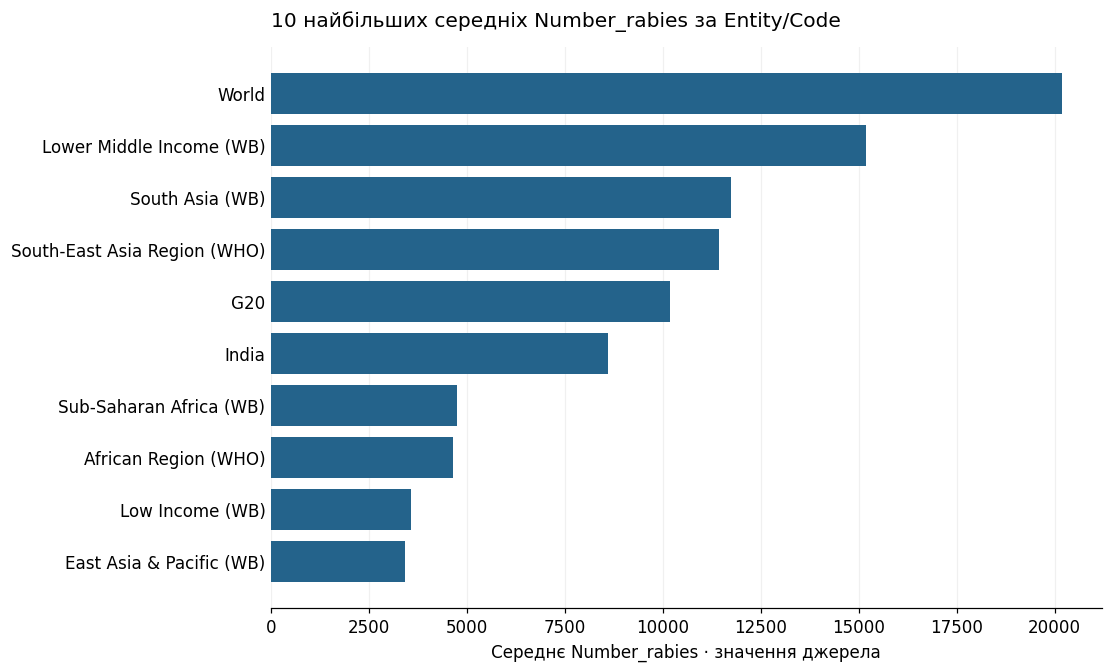

In [8]:
from textwrap import fill
plot_data = top10.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
ax.barh([fill(name, width=34) for name in plot_data["entity"]],
        plot_data["avg_number_rabies"].map(float), color="#24638b")
ax.set_title("10 найбільших середніх Number_rabies за Entity/Code", loc="left", pad=14)
ax.set_xlabel("Середнє Number_rabies · значення джерела")
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.ticklabel_format(axis="x", style="plain")
fig.savefig(PROJECT_ROOT / "results" / "03-rabies-top10.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## 4. Дата початку року та різниця в роках

`MAKE_DATE` створює 1 січня року спостереження. `CURRENT_DATE` повертає
поточну дату UTC, а `EXTRACT(YEAR FROM AGE(...))` — кількість повних
календарних років між цими датами. Дата у збереженому результаті належить
відповідному запуску та зміниться під час повторного виконання.

Запит охоплює всі спостереження; нижче показано перші 10 рядків,
а повний результат збережено в `results/04-dates.csv`.

In [9]:
dates = result("04-dates", sql_file("04_dates.sql"), rows=10)
print("Рядків у повному результаті:", len(dates))

-- Завдання 4. Повні календарні роки від 1 січня року спостереження.
-- CURRENT_DATE визначається датою початку поточної транзакції.

SELECT
    stats.observation_id,
    entity.entity,
    entity.code,
    stats.year,
    make_date(stats.year, 1, 1) AS year_start,
    CURRENT_DATE AS current_date,
    extract(year FROM age(CURRENT_DATE, make_date(stats.year, 1, 1)))::integer
        AS years_elapsed
FROM pandemic.case_stats AS stats
JOIN pandemic.entities AS entity USING (entity_id)
ORDER BY stats.observation_id;

,observation_id,entity,code,year,year_start,current_date,years_elapsed
0,1,Afghanistan,AFG,1980,1980-01-01,2026-10-18,46
1,2,Afghanistan,AFG,1981,1981-01-01,2026-10-18,45
2,3,Afghanistan,AFG,1982,1982-01-01,2026-10-18,44
3,4,Afghanistan,AFG,1983,1983-01-01,2026-10-18,43
4,5,Afghanistan,AFG,1984,1984-01-01,2026-10-18,42
5,6,Afghanistan,AFG,1985,1985-01-01,2026-10-18,41
6,7,Afghanistan,AFG,1986,1986-01-01,2026-10-18,40
7,8,Afghanistan,AFG,1987,1987-01-01,2026-10-18,39
8,9,Afghanistan,AFG,1988,1988-01-01,2026-10-18,38
9,10,Afghanistan,AFG,1989,1989-01-01,2026-10-18,37


Рядків у повному результаті: 10521


## 5. Дві незалежні функції

`years_since(integer)` обчислює різницю років до поточної дати;
`period_average(numeric, numeric)` ділить річне значення на довільний
додатний дільник. Функції не викликають одна одну.

Перша функція має атрибут `STABLE`, оскільки залежить від дати запуску;
друга — `IMMUTABLE`, оскільки залежить лише від аргументів.
Обидві є `STRICT`: `NULL`-аргумент дає `NULL`. Друга функція відхиляє
нульовий або від’ємний дільник і нескінченні чи NaN-аргументи.

In [10]:
show_sql(run.script("05_functions.sql"))

-- Завдання 5. Дві незалежні функції, доступні зі звичайного SQL-запиту.
-- years_since: повні календарні роки; NULL -> NULL; поточна дата -> STABLE.

CREATE OR REPLACE FUNCTION pandemic.years_since(source_year integer)
RETURNS integer
LANGUAGE sql
STABLE
STRICT
RETURN extract(
    year FROM pg_catalog.age(CURRENT_DATE, pg_catalog.make_date(source_year, 1, 1))
)::integer;

-- period_average: рівномірне середнє за частину року, а не окреме вимірювання.
-- Дільник повинен бути додатним; 0 та від'ємні значення викликають помилку.
-- NaN та нескінченності в обох аргументах також викликають помилку.
-- NULL в будь-якому аргументі -> NULL завдяки STRICT.
-- numeric / numeric зберігає дробову частину результату.
CREATE OR REPLACE FUNCTION pandemic.period_average(
    annual_cases numeric,
    divisor numeric
)
RETURNS numeric
LANGUAGE plpgsql
IMMUTABLE
STRICT
AS $function$
BEGIN
    IF annual_cases IN ('NaN'::numeric, 'Infinity'::numeric, '-Infinity'::numeric)
       OR divisor IN ('NaN'::numeric, 'Infinity'::numeric, '-Infinity'::numeric) THEN
        RAISE EXCEPTION 'Аргументи повинні бути скінченними числами'
            USING ERRCODE = '22023';
    END IF;
    IF divisor <= 0 THEN
        RAISE EXCEPTION 'Дільник повинен бути додатним: %', divisor
            USING ERRCODE = '22023';
    END IF;
    RETURN annual_cases / divisor;
END;
$function$;

### 5.1. Рік → повні роки до поточної дати

Для 1996 року та інших прикладів порівнюємо власну функцію
з вбудованим виразом із завдання 4.

Позначення `None`/`NaN` у виводі pandas відповідають SQL `NULL`; це пропуски, а не нулі.

In [11]:
year_examples = result("05-year-function", """
SELECT source_year,
       make_date(source_year, 1, 1) AS year_start,
       CURRENT_DATE AS current_date,
       extract(year FROM age(CURRENT_DATE, make_date(source_year, 1, 1)))::integer
           AS builtin_years,
       pandemic.years_since(source_year) AS function_years
FROM (VALUES (1996), (2000), (2023), (NULL::integer)) AS examples(source_year);
""")

SELECT source_year,
       make_date(source_year, 1, 1) AS year_start,
       CURRENT_DATE AS current_date,
       extract(year FROM age(CURRENT_DATE, make_date(source_year, 1, 1)))::integer
           AS builtin_years,
       pandemic.years_since(source_year) AS function_years
FROM (VALUES (1996), (2000), (2023), (NULL::integer)) AS examples(source_year);

,source_year,year_start,current_date,builtin_years,function_years
0,1996.0,1996-01-01,2026-10-18,30.0,30.0
1,2000.0,2000-01-01,2026-10-18,26.0,26.0
2,2023.0,2023-01-01,2026-10-18,3.0,3.0
3,NaN,None,2026-10-18,NaN,NaN


### 5.2. Річний показник → середнє за період

Після імпорту Number_rabies має тип `NUMERIC`; усі його непорожні значення
в цьому CSV є скінченними числами. Тому `WHERE number_rabies IS NOT NULL`
відбирає саме числові записи для другої функції, не вилучаючи пропуски
з основної таблиці.

Дільники **12**, **4**, **2** дають середнє за місяць, квартал і півріччя.
Це рівномірний розподіл річного значення, а не окремі спостереження цих періодів.
Обидві функції застосовано в наступному запиті; показано 6 рядків,
повний результат збережено в `results/06-function-examples.csv`.

In [12]:
function_examples = result("06-function-examples", sql_file("06_function_examples.sql"), rows=6)
print("Числових записів у повному результаті:", len(function_examples))

-- Обидві функції використано в одному запиті до нормалізованих даних.
-- number_rabies має тип numeric; обмеження таблиці відкидає NaN/Infinity.
-- Вибір лише непорожніх чисел задовольняє умову для функції кількості.
-- Дільники 12 / 4 / 2 означають місяць / квартал / півріччя відповідно.

SELECT
    stats.observation_id,
    entity.entity,
    entity.code,
    stats.year,
    pandemic.years_since(stats.year) AS years_elapsed,
    stats.number_rabies AS annual_number_rabies,
    pandemic.period_average(stats.number_rabies, 12::numeric) AS monthly_average,
    pandemic.period_average(stats.number_rabies, 4::numeric) AS quarterly_average,
    pandemic.period_average(stats.number_rabies, 2::numeric) AS half_year_average
FROM pandemic.case_stats AS stats
JOIN pandemic.entities AS entity USING (entity_id)
WHERE stats.number_rabies IS NOT NULL
ORDER BY entity.entity COLLATE "C", entity.code COLLATE "C" NULLS LAST,
         stats.year, stats.observation_id;

,observation_id,entity,code,year,years_elapsed,annual_number_rabies,monthly_average,quarterly_average,half_year_average
0,11,Afghanistan,AFG,1990,36,2.145772,0.17881433333333333333,0.53644300000000000000,1.07288600000000000000
1,12,Afghanistan,AFG,1991,35,2.3209748,0.19341456666666666667,0.58024370000000000000,1.16048740000000000000
2,38,Afghanistan,AFG,1992,34,2.6180408,0.21817006666666666667,0.65451020000000000000,1.30902040000000000000
3,39,Afghanistan,AFG,1993,33,2.8531172,0.23775976666666666667,0.71327930000000000000,1.42655860000000000000
4,40,Afghanistan,AFG,1994,32,2.9899871,0.24916559166666666667,0.74749677500000000000,1.49499355000000000000
5,13,Afghanistan,AFG,1995,31,3.126361,0.26053008333333333333,0.78159025000000000000,1.5631805000000000


Числових записів у повному результаті: 6780


### Дільники 12, 4, 2 та довільний додатний дільник

Для одного фактичного річного значення окремо показано результат кожного
дільника. Приклад із 7 демонструє, що функція не обмежена трьома періодами.

In [13]:
period_examples = result("06-period-divisors", """
WITH annual_value AS (
    SELECT number_rabies AS annual_number_rabies
    FROM pandemic.case_stats
    WHERE number_rabies IS NOT NULL
    ORDER BY observation_id
    LIMIT 1
)
SELECT annual_number_rabies, divisor, period_name,
       pandemic.period_average(annual_number_rabies, divisor) AS period_average
FROM annual_value
CROSS JOIN (VALUES
    (1, 12::numeric, 'місяць'),
    (2, 4::numeric, 'квартал'),
    (3, 2::numeric, 'півріччя'),
    (4, 7::numeric, 'одна сьома року')
) AS periods(position, divisor, period_name)
ORDER BY position;
""")

WITH annual_value AS (
    SELECT number_rabies AS annual_number_rabies
    FROM pandemic.case_stats
    WHERE number_rabies IS NOT NULL
    ORDER BY observation_id
    LIMIT 1
)
SELECT annual_number_rabies, divisor, period_name,
       pandemic.period_average(annual_number_rabies, divisor) AS period_average
FROM annual_value
CROSS JOIN (VALUES
    (1, 12::numeric, 'місяць'),
    (2, 4::numeric, 'квартал'),
    (3, 2::numeric, 'півріччя'),
    (4, 7::numeric, 'одна сьома року')
) AS periods(position, divisor, period_name)
ORDER BY position;

,annual_number_rabies,divisor,period_name,period_average
0,2.145772,12,місяць,0.17881433333333333333
1,2.145772,4,квартал,0.53644300000000000000
2,2.145772,2,півріччя,1.07288600000000000000
3,2.145772,7,одна сьома року,0.30653885714285714286


## Завершення

Результати SQL збережено як CSV у каталозі поточного запуску `results`.
Завершальна клітинка звіряє дані й функції та закриває окремий сервер PostgreSQL.

In [14]:
try:
    final_checks = check_project(run)
    counts = final_checks["checks"][0]["details"]
    display(pd.DataFrame([{
        "початкових рядків": counts["raw"],
        "сутностей": counts["entities"],
        "спостережень": counts["facts"],
        "умов виконано": final_checks["checks_passed"],
        "умов усього": final_checks["total_checks"],
    }]))
finally:
    run.close()
    assert run.closed
    print("Підключення й окремий сервер PostgreSQL закрито:", run.closed)
print("CSV-результати:", PROJECT_ROOT / "results")

,початкових рядків,сутностей,спостережень,умов виконано,умов усього
0,10521,245,10521,18,18


Підключення й окремий сервер PostgreSQL закрито: True
CSV-результати: /var/folders/tp/kf9whtnd5_s2_d1h5b29w5h00000gn/T/infectious-cases-m8at3ozc/project/results
